# Baseline y variantes de datos

**Objetivo:** fijar una referencia mínima (baseline) y medir si **cambiar los datos** —no el modelo— la mejora de forma demostrable.

| Pieza | Qué es |
|---|---|
| **Baseline** | `dummy` (clase mayoritaria), `kNN` (k = 5) y `Naive Bayes` sobre las variables originales (A), con imputación y escalado |
| **V1 — número de vistas** | 1 vista (0°), 2 vistas (0°+180°), 4 ecuatoriales (sin pedúnculo) y 5 vistas (baseline). Las features se re-agregan por fruto usando solo esas vistas |
| **V2 — balanceo** | sobremuestreo y submuestreo de las clases **solo en train** (dentro del ajuste, nunca antes de partir) |

**Protocolo:** misma partición congelada y mismos pliegues que Feature Engineering → comparaciones **pareadas**. CV estratificada solo sobre train + evaluación en val; **TEST no se toca**. Variante vs baseline: prueba t corregida para CV repetida (Nadeau & Bengio, 2003) con corrección de Holm. Métrica central: F1 macro; se reporta a la par el F1, recall y PR-AUC de **Fábrica**.

> Con `MODO_DEMO = True` se usan imágenes sintéticas: sirve para validar el flujo, **no** para sacar conclusiones.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import modelo_baseline as mb, fe_experimentos as fx, extraer_features as ef, ingesta, particion, informe
from src.remuestreo import indices_remuestreo

MODO_DEMO = False                      # <-- False con los datos reales
RAW  = ROOT / "data" / ("demo/raw" if MODO_DEMO else "raw")
PROC = ROOT / "data" / ("demo/processed" if MODO_DEMO else "processed")
cfg = mb.cargar_cfg_baseline()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
print({k: cfg[k] for k in ("semillas", "cv_folds", "modelos", "positivo", "metrica_central")})
print("Variantes de vistas:", cfg["variantes"]["vistas"], "| remuestreo:", cfg["variantes"]["remuestreo"])

{'semillas': [0, 1, 2], 'cv_folds': 5, 'modelos': ['dummy', 'knn', 'gnb'], 'positivo': 'Fabrica', 'metrica_central': 'f1_macro'}
Variantes de vistas: {'1vista': ['0'], '2vistas': ['0', '180'], '4ecuatoriales': ['0', '90', '180', '270']} | remuestreo: ['sobre', 'sub']


## 1. Datos (se generan los prerrequisitos que falten)

In [2]:
if not (PROC / "indice_frutos.csv").exists():  ingesta.main(RAW, PROC)
if not (PROC / "particion.csv").exists():      particion.main(PROC, forzar=False)      # se crea una vez y queda congelada
if not (PROC / "features_frutos.csv").exists(): ef.main(RAW, PROC, n_jobs=1)
df = fx.cargar_datos(PROC, ef.cargar_cfg())
tr, va, te = fx.dividir(df)
cuenta = tr["y"].value_counts()
HAY_CLASES = len(cuenta) >= 2 and cuenta.min() >= 5
print(f"Frutos train/val/test: {len(tr)}/{len(va)}/{len(te)}")
display(pd.crosstab(df["y"], df["subset"])[["train", "val", "test"]])
if not HAY_CLASES:
    print("[AVISO] Se necesitan al menos 2 categorías con >= 5 frutos en train: se omiten las secciones 2 a 5.")

Frutos train/val/test: 359/76/76


subset,train,val,test
y,,,
Extra,77,16,16
Fabrica,70,15,15
Primera,71,15,15
Segunda,71,15,15
Tercera,70,15,15


## 2. Ejecutar baseline y variantes
Cada configuración se evalúa con 5 pliegues × 3 semillas sobre train (más una evaluación en val) y todo queda registrado en `logs/baseline_runs/<corrida>/` y `logs/metrics_baseline.txt`.

In [3]:
if HAY_CLASES:
    res, comp, RUN_ID = mb.ejecutar(PROC, cfg, verbose=False)
    print("Corrida registrada:", RUN_ID)
    print(mb.tabla_baseline_md(res))

Corrida registrada: 20261030_183632
| Modelo | CV F1 macro | CV F1 Fábrica | CV recall Fábrica | CV PR-AUC Fábrica | VAL F1 macro | VAL F1 Fábrica | ajuste (s) | latencia (ms/fruto) |
|---|---|---|---|---|---|---|---|---|
| dummy | 0.071 ± 0.002 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.195 ± 0.001 | 0.070 | 0.000 | 0.01 | 945 |
| knn | 0.866 ± 0.048 | 0.863 ± 0.077 | 0.767 ± 0.116 | 0.947 ± 0.045 | 0.908 | 0.889 | 0.01 | 946 |
| gnb | 0.745 ± 0.089 | 0.758 ± 0.080 | 0.681 ± 0.080 | 0.864 ± 0.076 | 0.811 | 0.720 | 0.01 | 945 |



## 3. Baseline
**Qué buscar:** (1) que cualquier modelo supere con claridad al *dummy* (si no, las variables no aportan); (2) el recall y PR-AUC de Fábrica, la clase crítica; (3) el tamaño de la desviación ± entre pliegues: con pocos frutos es grande y limita lo que se puede concluir.

In [4]:
if HAY_CLASES:
    b = res[res.variante == "BASE"].set_index("modelo")
    show = pd.DataFrame({"CV F1 macro": [mb._ms(r, "f1_macro") for _, r in b.iterrows()],
                         "CV F1 Fábrica": [mb._ms(r, "f1_pos") for _, r in b.iterrows()],
                         "CV recall Fábrica": [mb._ms(r, "recall_pos") for _, r in b.iterrows()],
                         "VAL F1 macro": b.val_f1_macro.round(3)}, index=b.index)
    display(show)
    mejor = b.drop(index="dummy").cv_f1_macro_media.idxmax()
    cm = pd.read_json(sorted((ROOT / "logs/baseline_runs").glob("*"))[-1] / "matrices_confusion_val.json")
    m = cm[f"BASE|{mejor}"]; lab = m["labels"]
    display(pd.DataFrame(m["matriz"], index=[f"real {x}" for x in lab], columns=[f"pred {x}" for x in lab]))

,CV F1 macro,CV F1 Fábrica,CV recall Fábrica,VAL F1 macro
modelo,,,,
dummy,0.071 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.070
knn,0.866 ± 0.048,0.863 ± 0.077,0.767 ± 0.116,0.908
gnb,0.745 ± 0.089,0.758 ± 0.080,0.681 ± 0.080,0.811


,pred Extra,pred Fabrica,pred Primera,pred Segunda,pred Tercera
real Extra,15,0,0,1,0
real Fabrica,0,12,3,0,0
real Primera,0,0,14,0,1
real Segunda,1,0,0,14,0
real Tercera,1,0,0,0,14


## 4. Variantes de datos vs baseline
**Cómo leer:** Δ = diferencia media pareada por pliegue. `veredicto` solo dice *mejora* o *empeora* si el p ajustado por Holm es < 0,05; en otro caso **no hay evidencia**, aunque la media sea distinta. Con decenas de frutos, diferencias de 0,05–0,10 en F1 son ruido.

,modelo,variante,dif_media,pliegues_mejoran_pct,p_holm,veredicto
0,gnb,V1_1vista,-0.299,0.000,0.000,empeora
1,gnb,V1_2vistas,-0.102,0.000,0.266,sin evidencia
2,gnb,V1_4ecuatoriales,-0.042,13.333,1.000,sin evidencia
3,gnb,V2_sobremuestreo,-0.006,33.333,1.000,sin evidencia
4,gnb,V2_submuestreo,0.001,20.000,1.000,sin evidencia
5,knn,V1_1vista,-0.051,0.000,0.534,sin evidencia
6,knn,V1_2vistas,-0.021,20.000,1.000,sin evidencia
7,knn,V1_4ecuatoriales,0.004,53.333,1.000,sin evidencia
8,knn,V2_sobremuestreo,-0.008,20.000,1.000,sin evidencia
9,knn,V2_submuestreo,0.002,20.000,1.000,sin evidencia


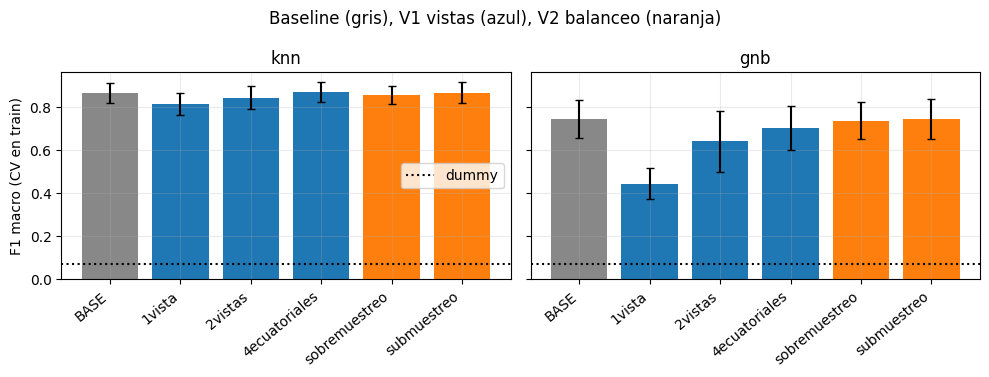

In [5]:
if HAY_CLASES:
    k = comp.pivot_table(index=["modelo", "variante"], columns="metrica", values=["dif_media", "p_holm"]).round(3)
    v = comp[comp.metrica == "f1_macro"][["modelo", "variante", "dif_media", "pliegues_mejoran_pct", "p_holm", "veredicto"]].round(3)
    display(v.sort_values(["modelo", "variante"]).reset_index(drop=True))

    orden = ["BASE", "V1_1vista", "V1_2vistas", "V1_4ecuatoriales", "V2_sobremuestreo", "V2_submuestreo"]
    col = {"BASE": "#888", "V1": "#1f77b4", "V2": "#ff7f0e"}
    mods = [m for m in cfg["modelos"] if m != "dummy"]
    fig, axs = plt.subplots(1, len(mods), figsize=(5 * len(mods), 3.8), sharey=True, squeeze=False)
    dummy = res.loc[res.modelo == "dummy", "cv_f1_macro_media"].iloc[0]
    for ax, m in zip(axs[0], mods):
        s = res[res.modelo == m].set_index("variante").reindex(orden)
        ax.bar(range(len(s)), s.cv_f1_macro_media, yerr=s.cv_f1_macro_std, capsize=3,
               color=[col["BASE"] if x == "BASE" else col[x[:2]] for x in s.index])
        ax.axhline(dummy, color="k", ls=":", label="dummy"); ax.set_title(m)
        ax.set_xticks(range(len(s))); ax.set_xticklabels([x.replace("V1_", "").replace("V2_", "") for x in s.index], rotation=40, ha="right")
    axs[0][0].set_ylabel("F1 macro (CV en train)"); axs[0][0].legend()
    plt.suptitle("Baseline (gris), V1 vistas (azul), V2 balanceo (naranja)"); plt.tight_layout(); plt.show()

## 5. Costo de las variantes y qué hace el remuestreo
- **Vistas:** menos imágenes por fruto = captura y extracción más rápidas. El gráfico enfrenta F1 con la latencia de extracción (medida aquí; solo features).
- **Balanceo:** muestra cuántos frutos ve el modelo en train antes y después del remuestreo.

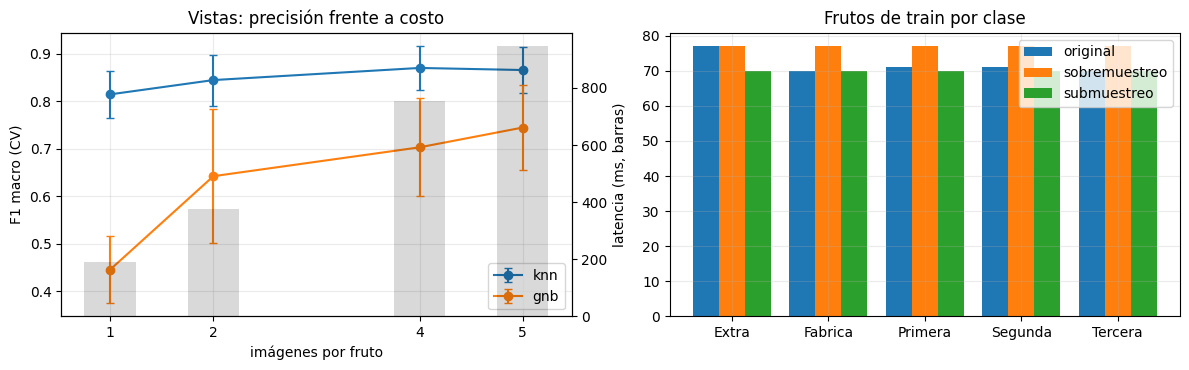

Latencia por fruto (ms): {1: 190.0, 2: 377.0, 4: 753.0, 5: 945.0}


In [6]:
if HAY_CLASES:
    nv = {"BASE": 5, "V1_4ecuatoriales": 4, "V1_2vistas": 2, "V1_1vista": 1}
    vs = res[res.variante.isin(nv)].assign(nv=lambda d: d.variante.map(nv))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8)); ax2 = axs[0].twinx()
    for m in mods:
        s = vs[vs.modelo == m].sort_values("nv")
        axs[0].errorbar(s.nv, s.cv_f1_macro_media, yerr=s.cv_f1_macro_std, marker="o", capsize=3, label=m)
    l = vs[vs.modelo == mods[0]].sort_values("nv"); ax2.bar(l.nv, l.latencia_total_ms_fruto, width=.5, alpha=.15, color="k")
    axs[0].set_xlabel("imágenes por fruto"); axs[0].set_ylabel("F1 macro (CV)"); ax2.set_ylabel("latencia (ms, barras)"); ax2.grid(False)
    axs[0].set_xticks(sorted(nv.values())); axs[0].legend(); axs[0].set_title("Vistas: precisión frente a costo")
    y = tr["y"].to_numpy(); cats = sorted(set(y)); w = .27
    for i, (nom, idx) in enumerate([("original", np.arange(len(y))), ("sobremuestreo", indices_remuestreo(y, "sobre")),
                                    ("submuestreo", indices_remuestreo(y, "sub"))]):
        axs[1].bar(np.arange(len(cats)) + i * w, [(y[idx] == c).sum() for c in cats], w, label=nom)
    axs[1].set_xticks(np.arange(len(cats)) + w); axs[1].set_xticklabels(cats); axs[1].legend(); axs[1].set_title("Frutos de train por clase")
    plt.tight_layout(); plt.show()
    print("Latencia por fruto (ms):", vs.groupby("nv").latencia_total_ms_fruto.mean().round(0).to_dict())

## 6. Decisiones (completar con datos reales)
| # | Pregunta | Evidencia | Decisión |
|---|---|---|---|
| 1 | ¿El baseline supera con claridad al dummy? ¿En Fábrica? | §3 | |
| 2 | ¿Usar menos vistas pierde precisión demostrable? ¿Cuánto cuesta cada vista? | §4–5 | |
| 3 | ¿El balanceo mejora con evidencia (p Holm < 0,05)? ¿O conviene recolectar más frutos? | §4–5 | |
| 4 | ¿Qué configuración de datos se usa en el siguiente paso (MVCNN y multitarea)? | §4 | |
| 5 | ¿Qué limitaciones de los datos condicionan estas conclusiones (clases chicas, color sin corregir)? | EDA / FE | |

## 7. Generar el informe
Reúne datos, EDA, Feature Engineering, baseline y variantes en un documento Word y un Markdown con las cifras reales de esta corrida.

In [ ]:
if HAY_CLASES:
    r = informe.generar(PROC, ROOT / ("informe_demo" if MODO_DEMO else "informe"))
    print("Informe generado:", r["docx"])